# Tech Challenge — Fase 3 · Análise completa
Predição de alfabetização infantil a partir da camada **Gold** da Fase 2.

Este notebook executa a pipeline de ponta a ponta: dados → EDA → pré-processamento →
treino/validação → interpretabilidade. Todo o código reutilizável vive em `src/`.

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath('..'))  # raiz do repo no path
from IPython.display import Image, display
import json, pandas as pd

## 1. Dados — da Gold ao dataset supervisionado
Cada município-ano vira duas linhas (alfabetizado / não) com peso = nº de alunos.
Split temporal: treino 2023+2024, teste 2025.

In [2]:
from src.preprocessing.dataset import montar, FEATURES, FEATURES_NUMERICAS, FEATURES_CATEGORICAS
d = montar()
print('Treino:', d['treino'].shape[0], 'linhas |', f"{int(d['peso_treino'].sum()):,}", 'alunos')
print('Teste: ', d['teste'].shape[0], 'linhas |', f"{int(d['peso_teste'].sum()):,}", 'alunos')
print('Features:', len(FEATURES), f'({len(FEATURES_NUMERICAS)} num + {len(FEATURES_CATEGORICAS)} cat)')
d['treino'].head(3)

Treino: 22284 linhas | 5,274,494 alunos
Teste:  11142 linhas | 2,637,247 alunos
Features: 21 (18 num + 3 cat)


,id_municipio,nome_municipio,ano,indicador_ano_anterior_pct,matriculas_ano_anterior,meta_pactuada_pct,idhm,idhm_educacao,idhm_renda,renda_per_capita,...,pct_6a14_fund_sem_atraso,pct_agua_encanada,pct_energia_eletrica,populacao_total,capital,sigla_uf,regiao,porte_municipio,y,peso
0,1100072,Corumbiara,2023,NaN,NaN,62.3,0.613,0.473,0.630,402.15,...,72.08,93.24,97.81,8783.0,0,RO,Norte,PEQUENO,1,68
1,1100072,Corumbiara,2024,50.6,135.0,62.3,0.613,0.473,0.630,402.15,...,72.08,93.24,97.81,8783.0,0,RO,Norte,PEQUENO,1,63
2,1100106,Guajará-Mirim,2023,NaN,NaN,62.3,0.657,0.519,0.663,494.69,...,51.27,93.26,97.71,41656.0,0,RO,Norte,MEDIO,1,313


## 2. Análise exploratória
Distribuições, padrões regionais, correlações e o gradiente por IDHM.

In [3]:
from src.visualization.eda import gerar as gerar_eda
resumo_eda = gerar_eda()
print(json.dumps(resumo_eda, indent=2, ensure_ascii=False))

{
  "n_municipios": 5571,
  "anos": [
    2023,
    2024,
    2025
  ],
  "media_indicador_por_ano": {
    "2023": 48.8,
    "2024": 49.6,
    "2025": 56.2
  },
  "media_por_regiao_2025": {
    "Nordeste": 48.3,
    "Norte": 49.1,
    "Sul": 56.5,
    "Sudeste": 63.8,
    "Centro-Oeste": 65.2
  },
  "top_correlacoes_com_alvo": {
    "indicador_ano_anterior_pct": 0.907,
    "meta_pactuada_pct": 0.657,
    "idhm_educacao": 0.576,
    "pct_criancas_dom_sem_fund": -0.538,
    "idhm": 0.525,
    "pct_6a14_fund_sem_atraso": 0.47
  },
  "media_por_quartil_idhm_2025": {
    "Q1 (menor)": 41.9,
    "Q2": 55.2,
    "Q3": 62.0,
    "Q4 (maior)": 65.9
  },
  "municipios_sem_contexto": 21
}


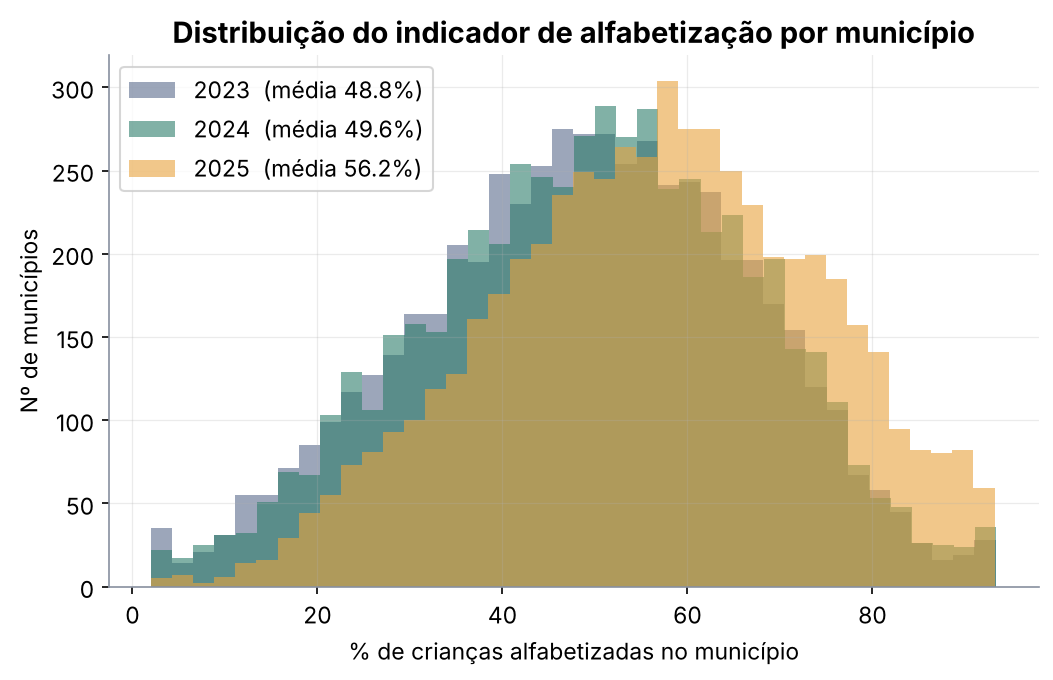

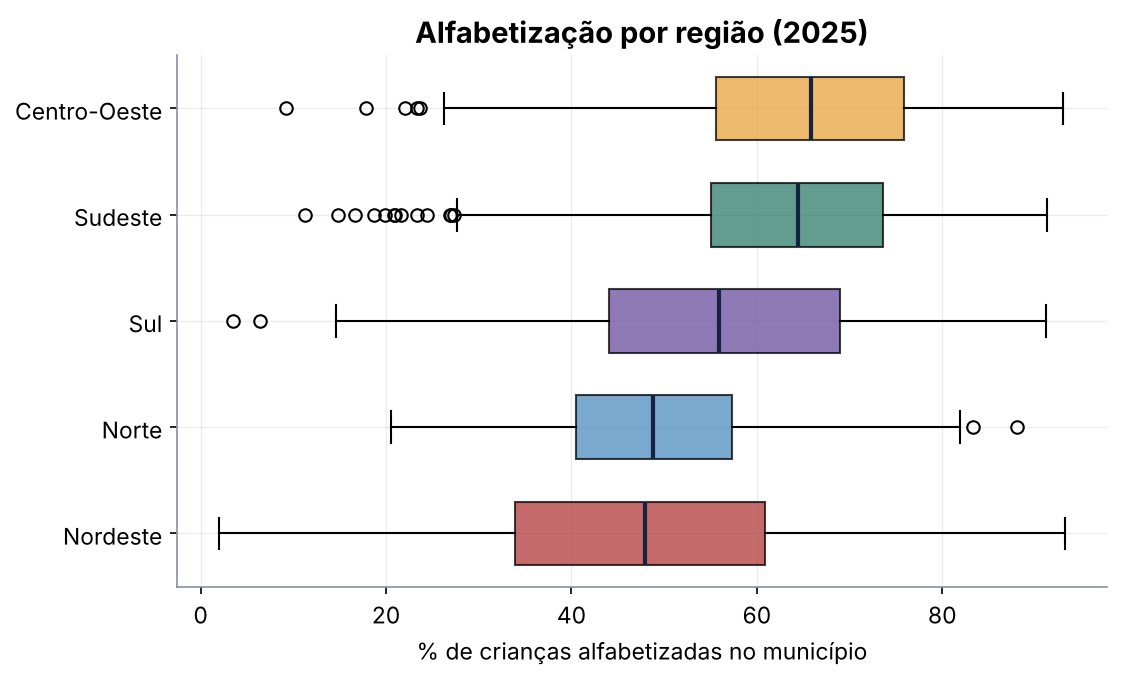

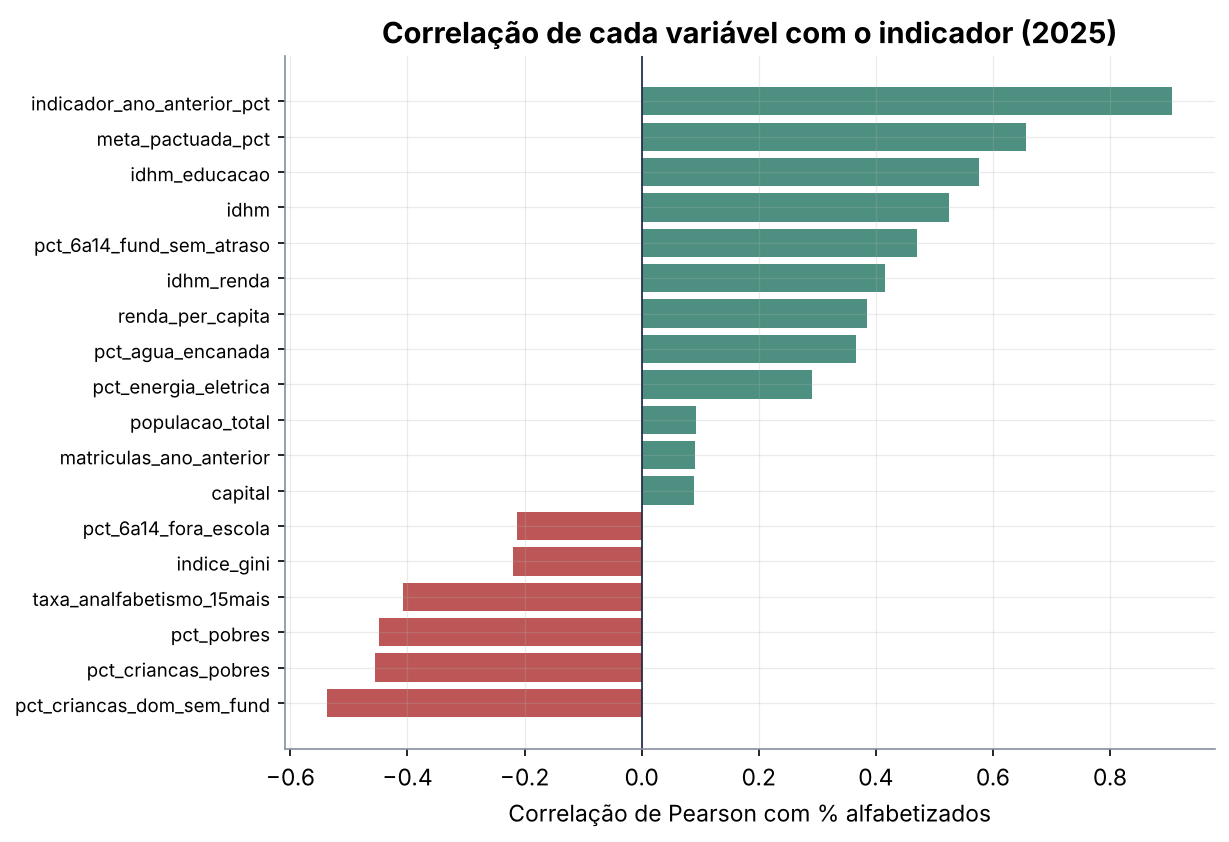

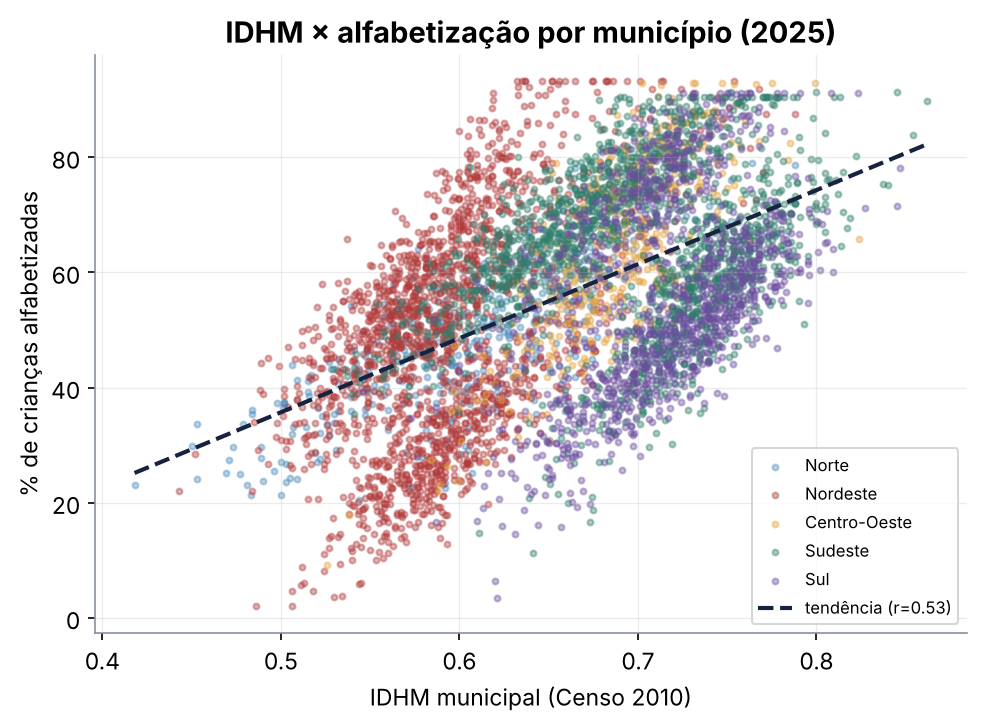

In [4]:
for img in ['eda_distribuicao_indicador','eda_por_regiao','eda_correlacao_alvo','eda_idhm_scatter']:
    display(Image(f'../images/{img}.png'))

## 3. Modelagem — treino, validação cruzada por município e teste out-of-time
Três modelos candidatos; seleção pela CV; avaliação em 2025.

In [5]:
from src.modeling.treinar import executar
rel = executar()
print('Melhor modelo:', rel['melhor_modelo'])
pd.DataFrame({m: {**{'cv_auc': r['cv']['auc_cv_media']}, **r['teste_2025']}
              for m, r in rel['resultados'].items()}).T.round(3)


### regressao_logistica


  CV ROC-AUC: 0.699 ± 0.010


  Teste 2025: roc_auc=0.702 | pr_auc=0.800 | f1=0.777 | precisao=0.716 | recall=0.849 | acuracia=0.686 | brier=0.203

### random_forest


  CV ROC-AUC: 0.694 ± 0.009


  Teste 2025: roc_auc=0.693 | pr_auc=0.794 | f1=0.767 | precisao=0.719 | recall=0.822 | acuracia=0.678 | brier=0.207

### hist_gradient_boosting


  CV ROC-AUC: 0.690 ± 0.011


  Teste 2025: roc_auc=0.678 | pr_auc=0.777 | f1=0.781 | precisao=0.695 | recall=0.891 | acuracia=0.677 | brier=0.215

==> Melhor modelo (CV): regressao_logistica


Melhor modelo: regressao_logistica


,cv_auc,acuracia,precisao,recall,f1,roc_auc,pr_auc,brier
regressao_logistica,0.699,0.686,0.716,0.849,0.777,0.702,0.800,0.203
random_forest,0.694,0.678,0.719,0.822,0.767,0.693,0.794,0.207
hist_gradient_boosting,0.690,0.677,0.695,0.891,0.781,0.678,0.777,0.215


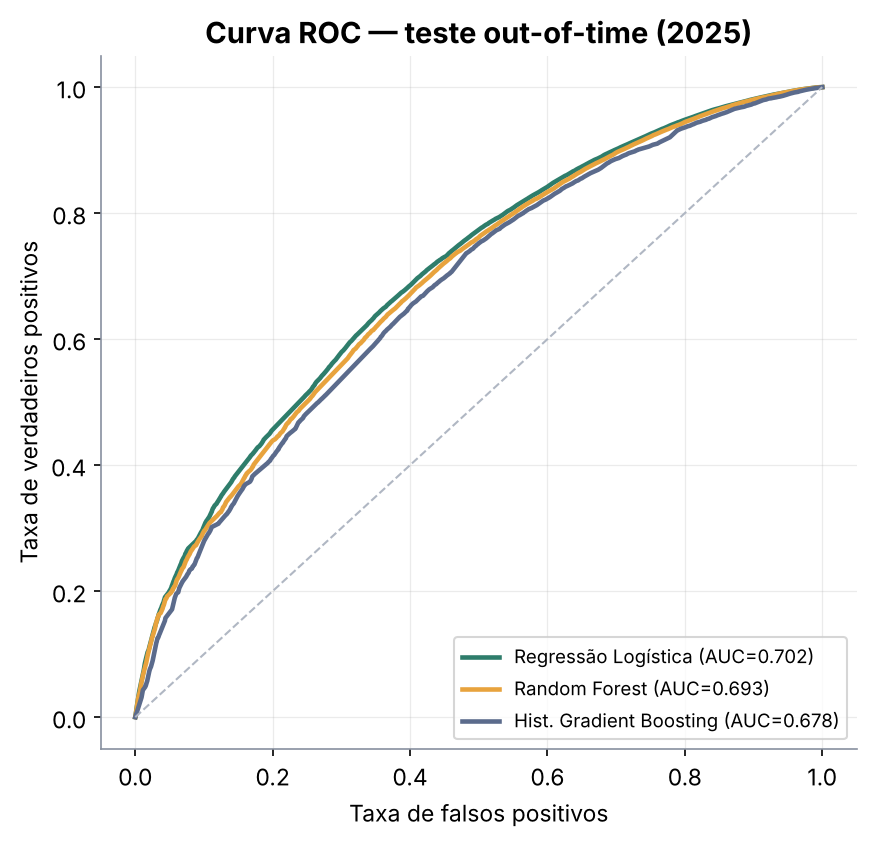

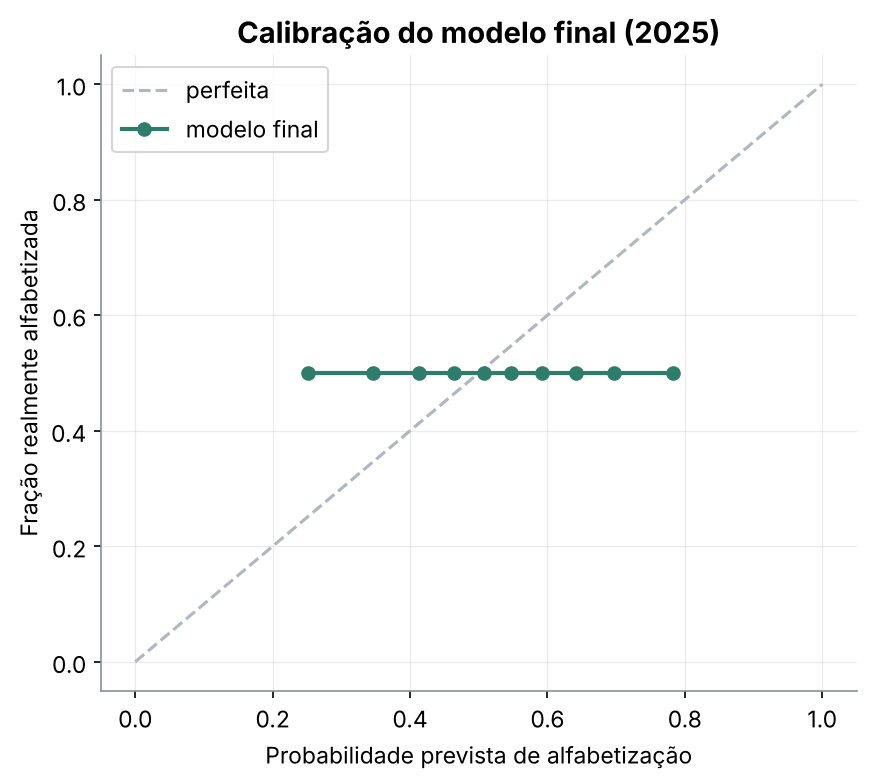

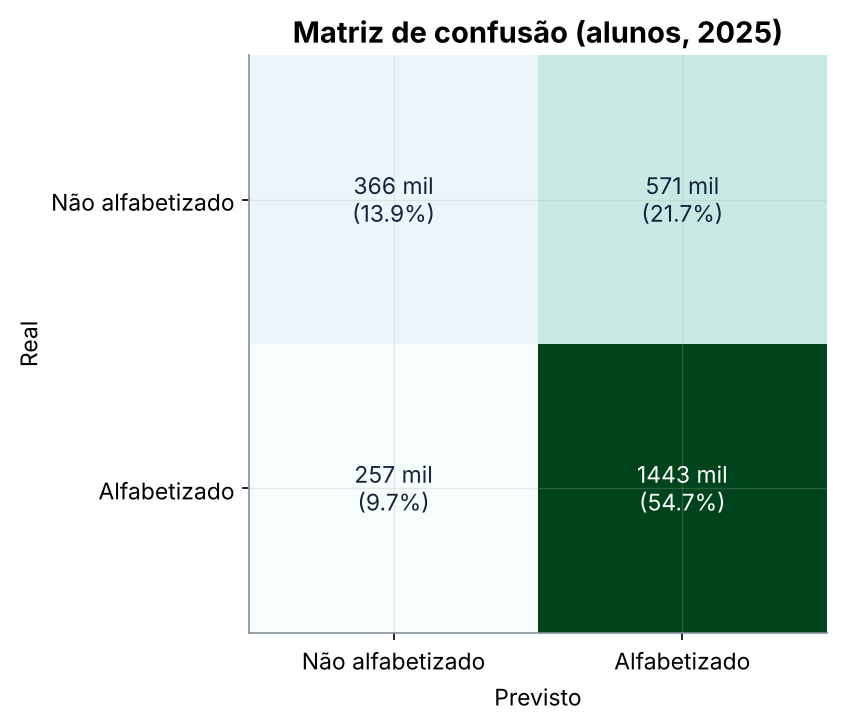

In [6]:
display(Image('../images/resultado_roc.png'))
display(Image('../images/resultado_calibracao.png'))
display(Image('../images/resultado_matriz_confusao.png'))

## 4. Interpretabilidade — Feature Importance + SHAP
Quais variáveis mais influenciam a predição.

In [7]:
from src.evaluation.interpretabilidade import gerar as gerar_interp
interp = gerar_interp()
print(json.dumps(interp, indent=2, ensure_ascii=False))

/usr/local/lib/python3.13/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Background dataset has 500 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=500 when initializing the masker.


{
  "top_permutacao": {
    "idhm_educacao": 0.1004,
    "meta_pactuada_pct": 0.0486,
    "regiao": 0.0444,
    "sigla_uf": 0.0336,
    "pct_criancas_pobres": 0.0324,
    "pct_pobres": 0.0114,
    "pct_6a14_fund_sem_atraso": 0.0093,
    "idhm": 0.0057
  },
  "top_coeficientes_abs": {
    "regiao_Nordeste": 0.72,
    "sigla_uf_DF": 0.718,
    "sigla_uf_SP": 0.612,
    "sigla_uf_PA": 0.535,
    "idhm_educacao": 0.511,
    "regiao_Sul": 0.507,
    "meta_pactuada_pct": 0.482,
    "sigla_uf_PI": 0.355
  },
  "top_shap": {
    "idhm_educacao": 0.42,
    "meta_pactuada_pct": 0.344,
    "regiao_Nordeste": 0.325,
    "pct_criancas_pobres": 0.295,
    "pct_pobres": 0.2,
    "regiao_Sul": 0.165,
    "pct_6a14_fund_sem_atraso": 0.146,
    "sigla_uf_SP": 0.122
  }
}


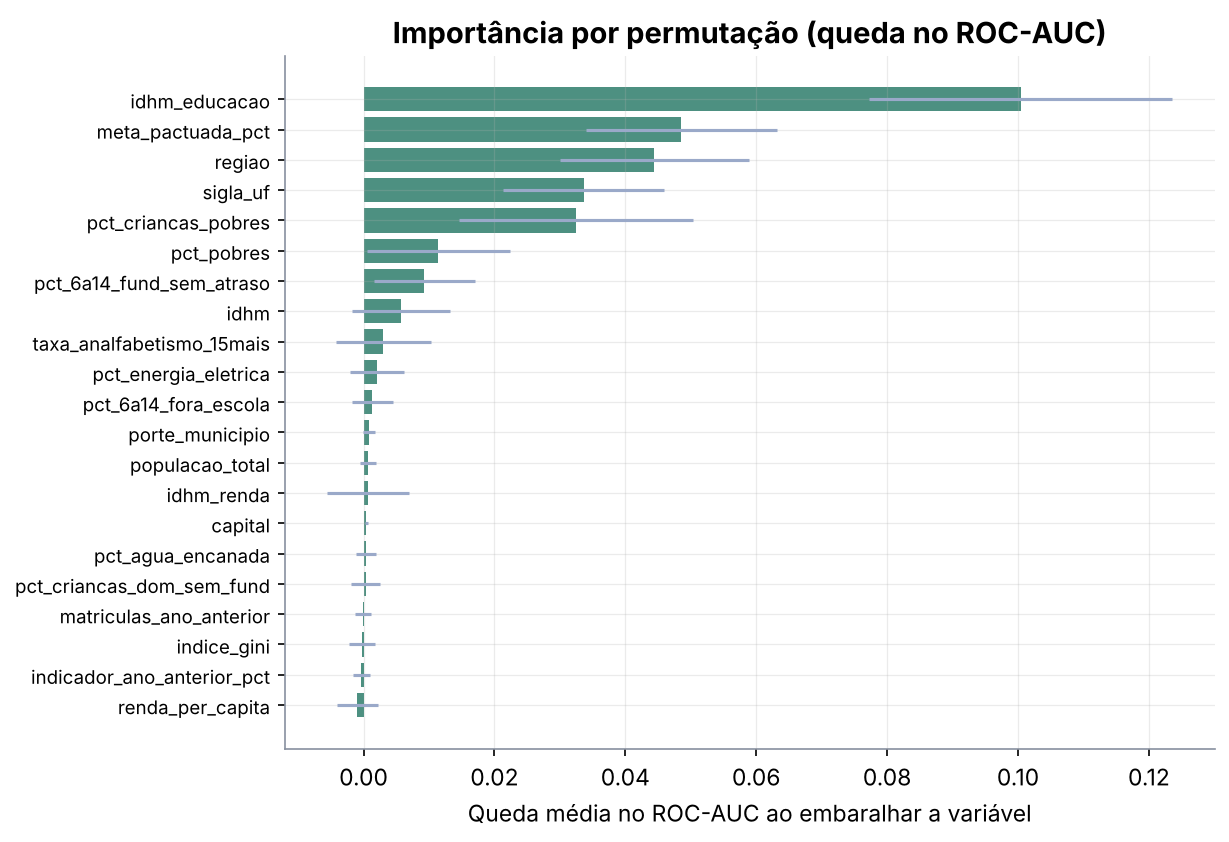

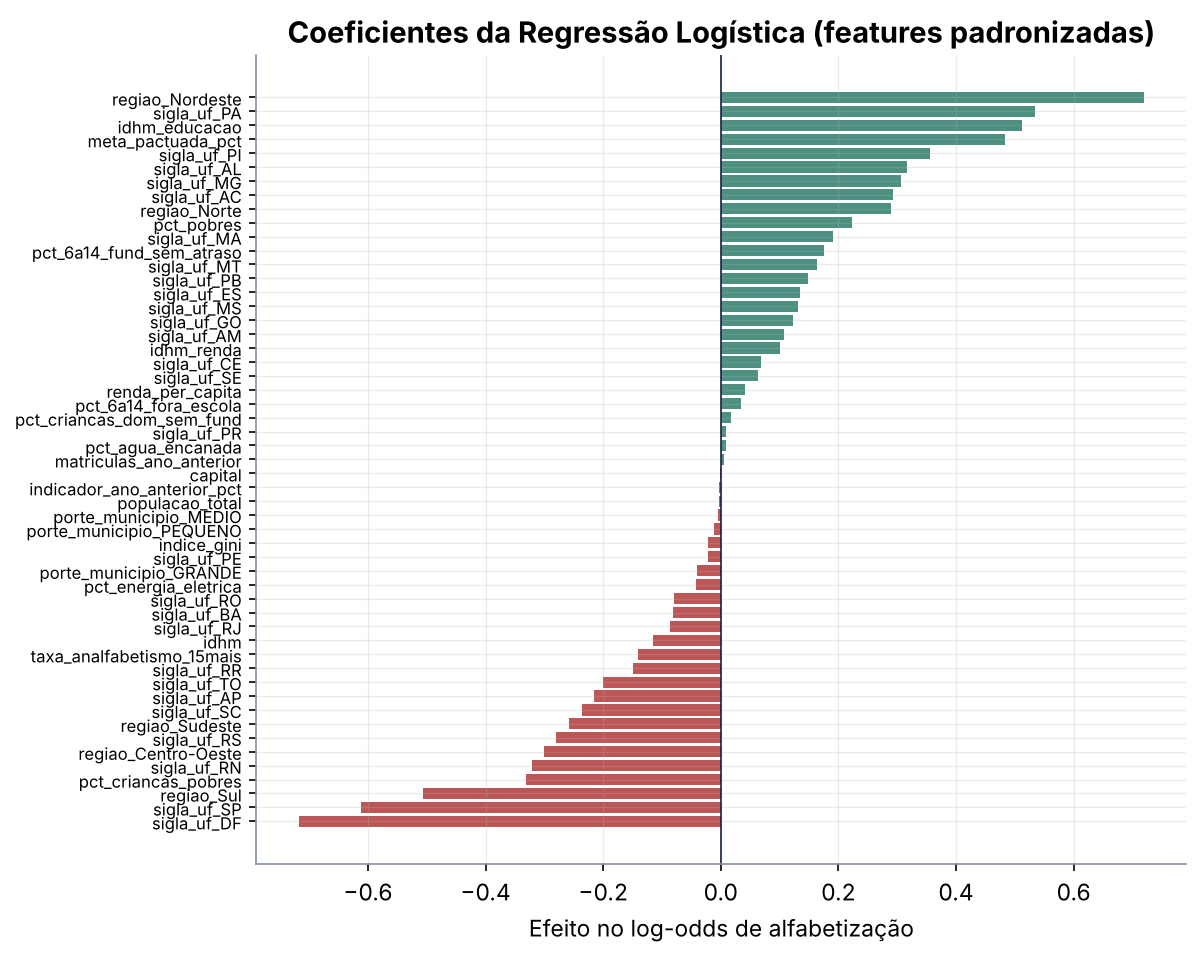

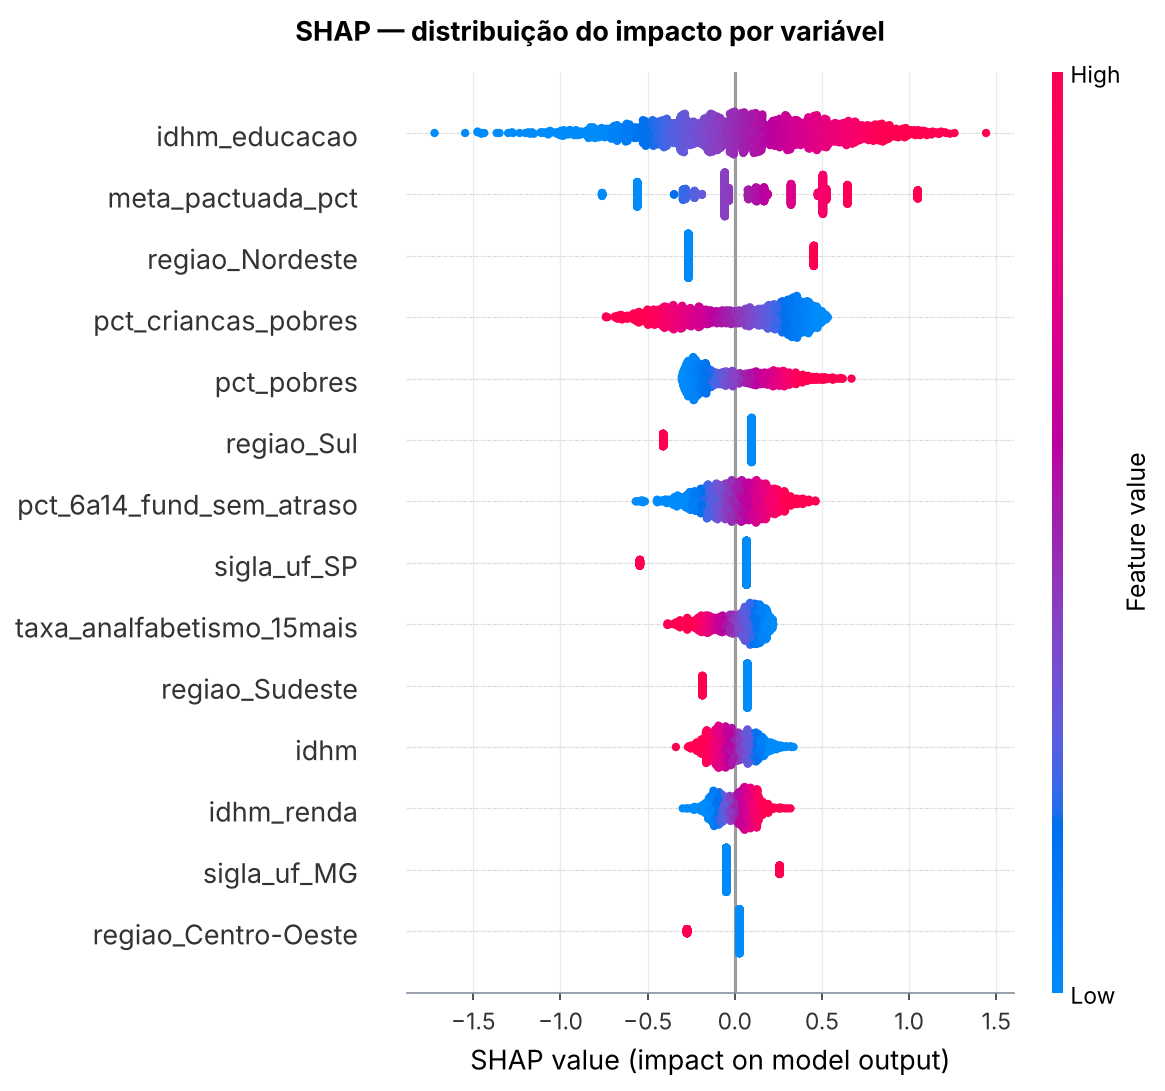

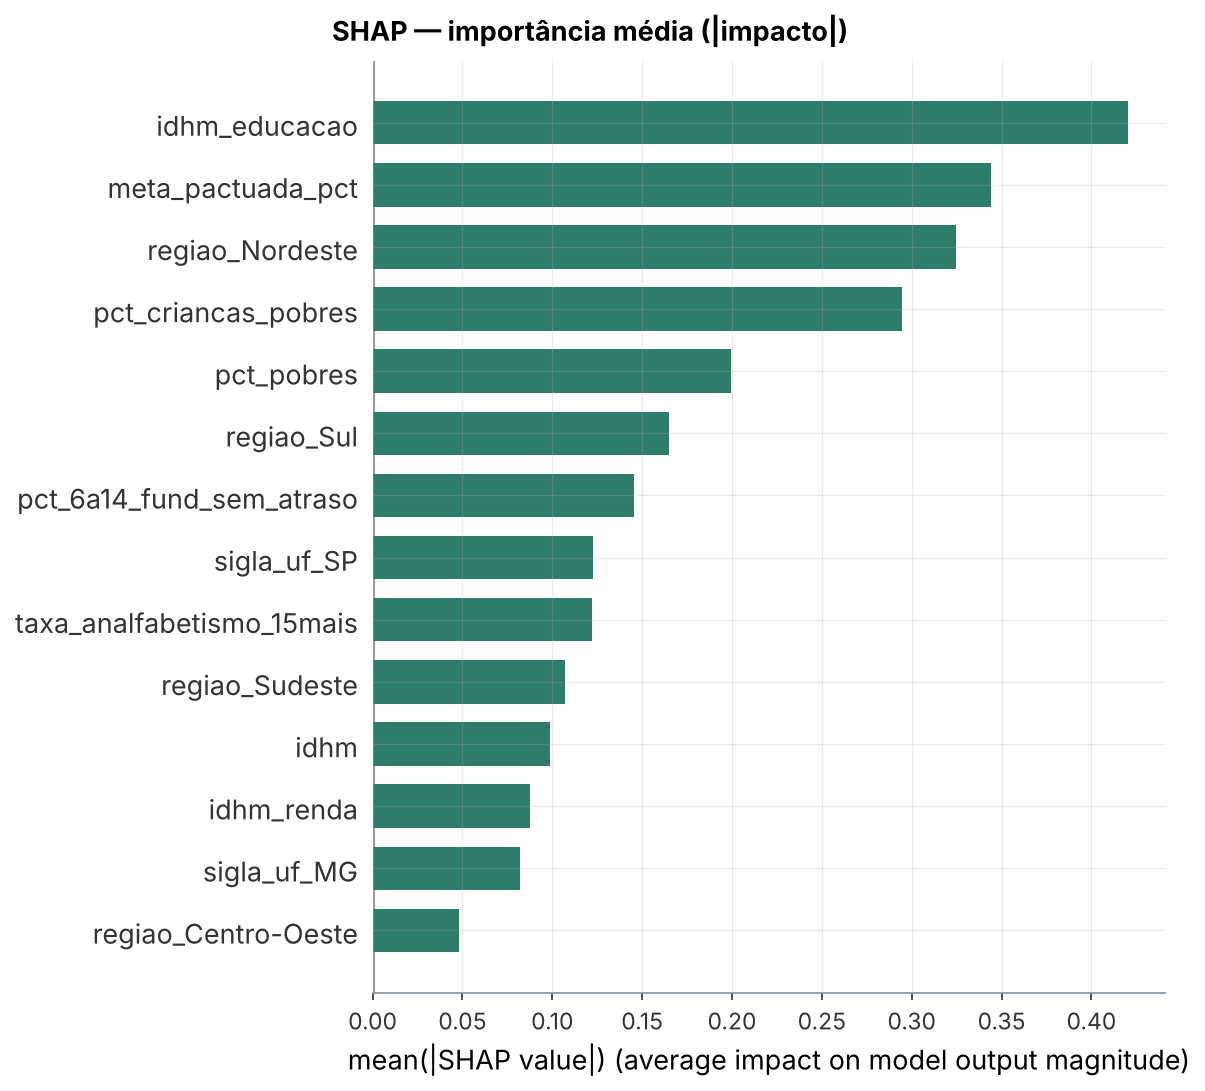

In [8]:
for img in ['importancia_permutacao','importancia_coeficientes','shap_beeswarm','shap_barra']:
    display(Image(f'../images/{img}.png'))

## 5. Risco por município e conclusões
Ranking de risco para 2025 e síntese dos achados.

{
  "n_municipios_risco_alto_2025": 2402,
  "top5_municipios_risco": [
    {
      "nome_municipio": "Itapicuru",
      "sigla_uf": "BA",
      "prob_alfabetizacao": 0.107
    },
    {
      "nome_municipio": "João Dias",
      "sigla_uf": "RN",
      "prob_alfabetizacao": 0.132
    },
    {
      "nome_municipio": "Ibiquera",
      "sigla_uf": "BA",
      "prob_alfabetizacao": 0.134
    },
    {
      "nome_municipio": "Pedro Alexandre",
      "sigla_uf": "BA",
      "prob_alfabetizacao": 0.136
    },
    {
      "nome_municipio": "Melgaço",
      "sigla_uf": "PA",
      "prob_alfabetizacao": 0.137
    }
  ]
}


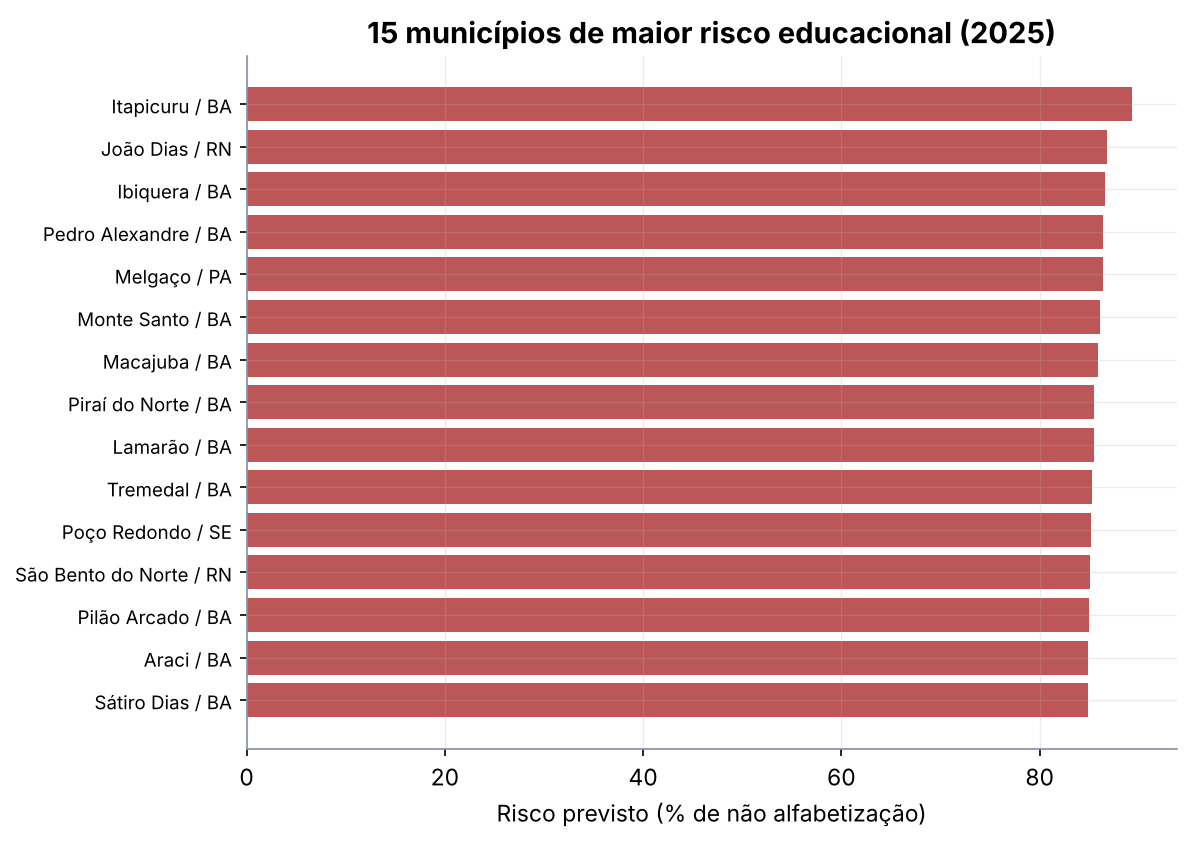

,id_municipio,nome_municipio,sigla_uf,prob_alfabetizacao,risco
0,2916500,Itapicuru,BA,0.106550,0.893450
1,2405900,João Dias,RN,0.132082,0.867918
2,2912608,Ibiquera,BA,0.133924,0.866076
3,2924207,Pedro Alexandre,BA,0.136173,0.863827
4,1504505,Melgaço,PA,0.136571,0.863429
5,2921500,Monte Santo,BA,0.138793,0.861207
6,2919603,Macajuba,BA,0.141110,0.858890
7,2924678,Piraí do Norte,BA,0.145387,0.854613
8,2919108,Lamarão,BA,0.145543,0.854457
9,2931806,Tremedal,BA,0.147426,0.852574


In [9]:
from src.visualization.resultados import gerar as gerar_result
ins = gerar_result()
print(json.dumps(ins, indent=2, ensure_ascii=False))
display(Image('../images/resultado_risco_municipios.png'))
pd.read_csv('../reports/municipios_risco_2025.csv').head(10)

**Síntese.** O modelo final (Regressão Logística) atinge ROC-AUC 0,70 no teste
out-of-time de 2025. Os fatores de maior impacto são o subíndice de educação do IDHM, a
meta pactuada, a região (Nordeste) e a pobreza infantil. O valor prático é ordenar
municípios por risco **antes** da avaliação, direcionando apoio técnico a quem mais
precisa. Limitações e evoluções estão no README.